# Task 2: Test Gaussian covariance and rendering on Colab

Open this notebook in VS Code and connect it to a **Google Colab GPU runtime** using the Colab extension. Run the cells from top to bottom. The notebook clones or fast-forwards the assignment from GitHub, so **commit and push your Task 2 changes to the repository's default branch before running**; uncommitted local changes are not available to the remote runtime. The notebook stops if CUDA or `nvcc` is unavailable. The extension build can take several minutes.

In [1]:
import os
import pathlib
import subprocess

repo_url = 'https://github.com/jon-of-us/gaussian-splatting-homwork.git'
assignment_root = pathlib.Path('/content/hw1_2026_student')

if (assignment_root / '.git').is_dir():
    subprocess.run(
        ['git', '-C', str(assignment_root), 'pull', '--ff-only'],
        check=True,
    )
elif assignment_root.exists():
    raise FileExistsError(
        f'{assignment_root} exists but is not a Git checkout. '
        'Rename it in the Colab runtime, then rerun this cell.'
    )
else:
    subprocess.run(
        ['git', 'clone', '--depth', '1', repo_url, str(assignment_root)],
        check=True,
    )

required_files = [
    assignment_root / 'gaussian_model.py',
    assignment_root / 'submodules/diff-gaussian-rasterization/cuda_rasterizer/forward.cu',
    assignment_root / 'scripts/setup_environment.sh',
    assignment_root / 'assets/gs_cloud.ply',
]
missing_files = [str(path) for path in required_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f'Repository checkout is missing required files: {missing_files}')

os.chdir(assignment_root)
print(f'Assignment directory: {pathlib.Path.cwd()}')

Assignment directory: /content/hw1_2026_student


In [2]:
import sys
import torch
import torchvision
import torch.utils.cpp_extension

if not torch.cuda.is_available():
    raise RuntimeError(
        'CUDA is unavailable. Connect this notebook to a Colab GPU runtime, then rerun.'
    )

cuda_home = torch.utils.cpp_extension.CUDA_HOME
if cuda_home is None:
    raise RuntimeError('CUDA Toolkit was not found. Use a Colab GPU runtime with nvcc installed.')

nvcc = pathlib.Path(cuda_home) / 'bin' / 'nvcc'
if not nvcc.is_file():
    raise FileNotFoundError(f'CUDA compiler was not found: {nvcc}')

subprocess.run(['nvidia-smi'], check=True)
subprocess.run([str(nvcc), '--version'], check=True)
print(f'Python: {sys.version.split()[0]}')
print(f'PyTorch: {torch.__version__}')
print(f'torchvision: {torchvision.__version__}')
print(f'PyTorch CUDA: {torch.version.cuda}')
print(f'GPU: {torch.cuda.get_device_name(0)}')

Python: 3.13.16
PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
PyTorch CUDA: 13.0
GPU: Tesla T4


## Build the CUDA rasterizer

This calls the repository helper, which checks the environment, installs the remaining requirements, and compiles the extension using the active notebook Python. Build errors are surfaced in the cell output.

In [3]:
import os
import sys
import subprocess

build_env = os.environ.copy()
build_env['HW1_PYTHON'] = sys.executable
build_env['MAX_JOBS'] = '2'
subprocess.run(
    ['bash', 'scripts/setup_environment.sh'],
    cwd=assignment_root,
    env=build_env,
    check=True,
)

CompletedProcess(args=['bash', 'scripts/setup_environment.sh'], returncode=0)

Rendering all five views exercises `get_covariance` and the CUDA `computeCov2D` path end to end. This avoids a separate full-model eigenvalue check, which can be both memory-intensive and sensitive to float32 round-off.

Rendered 5 views in 6.46 seconds.


### Camera 0: 00000.png

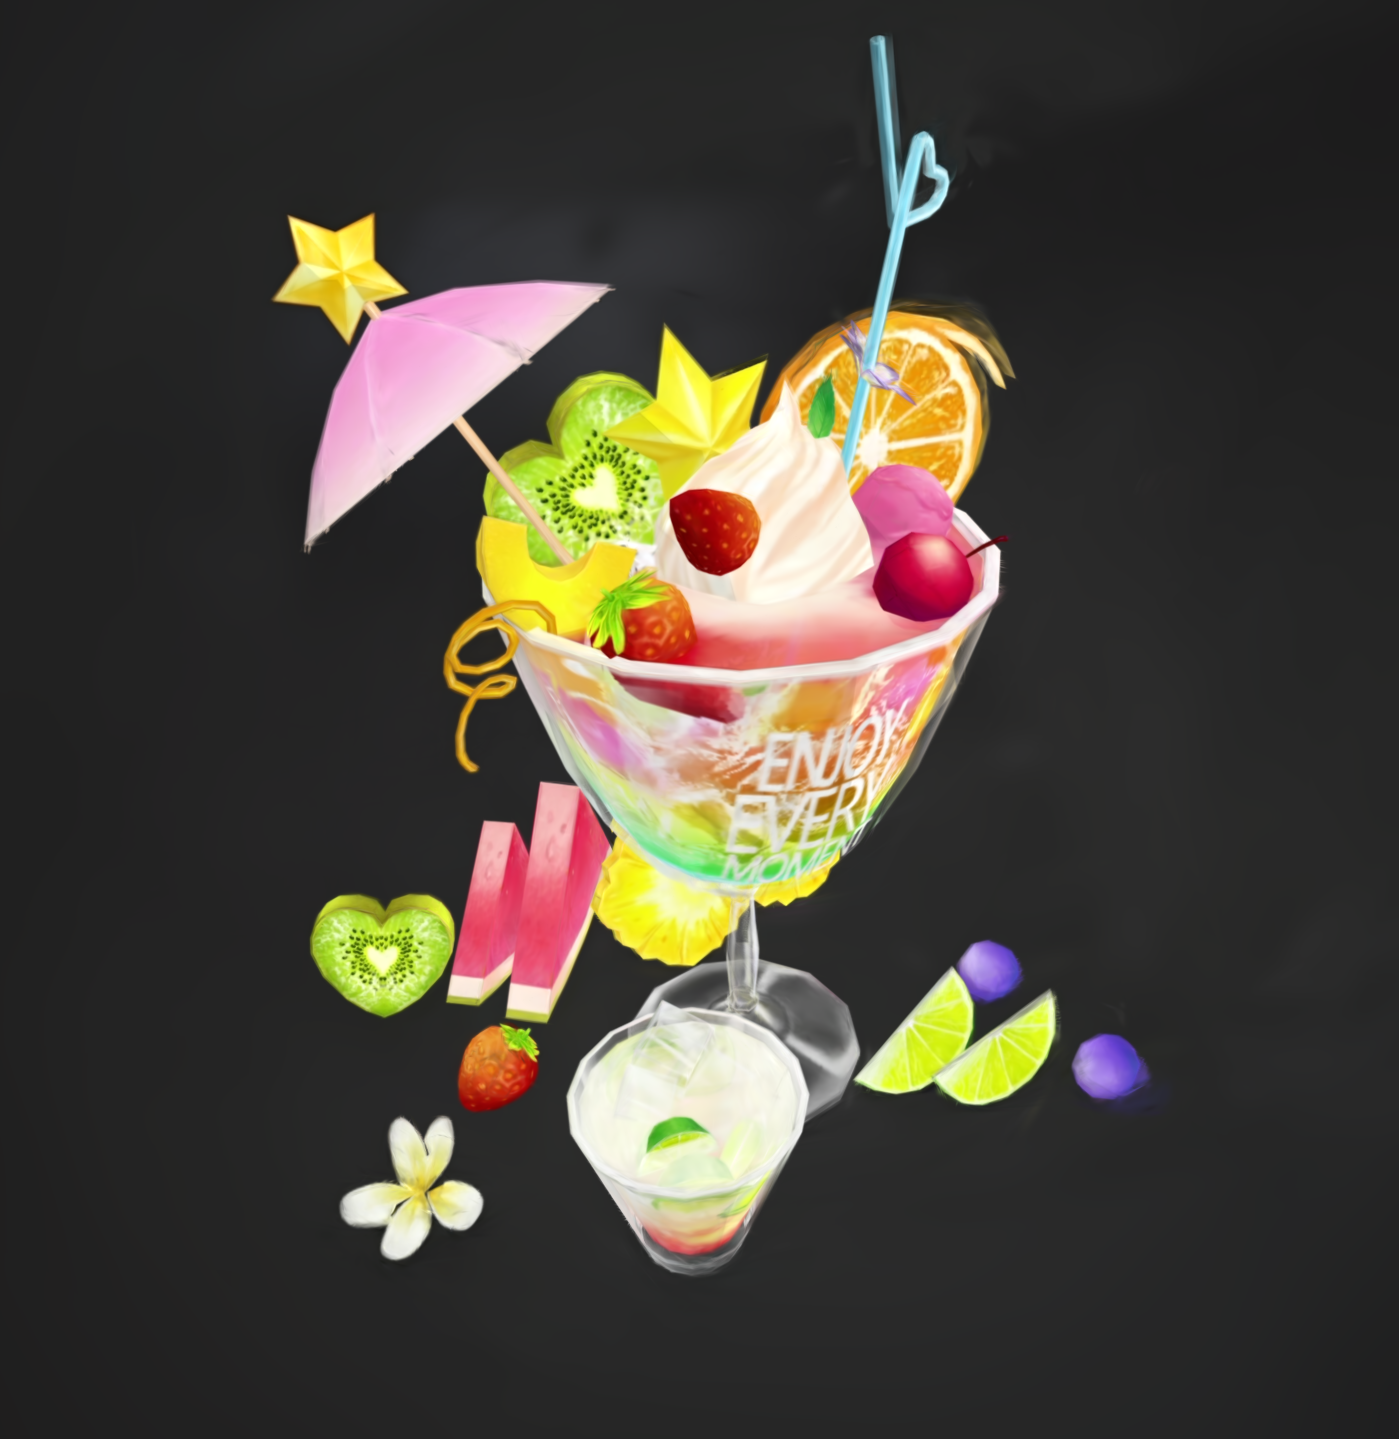

### Camera 1: 00001.png

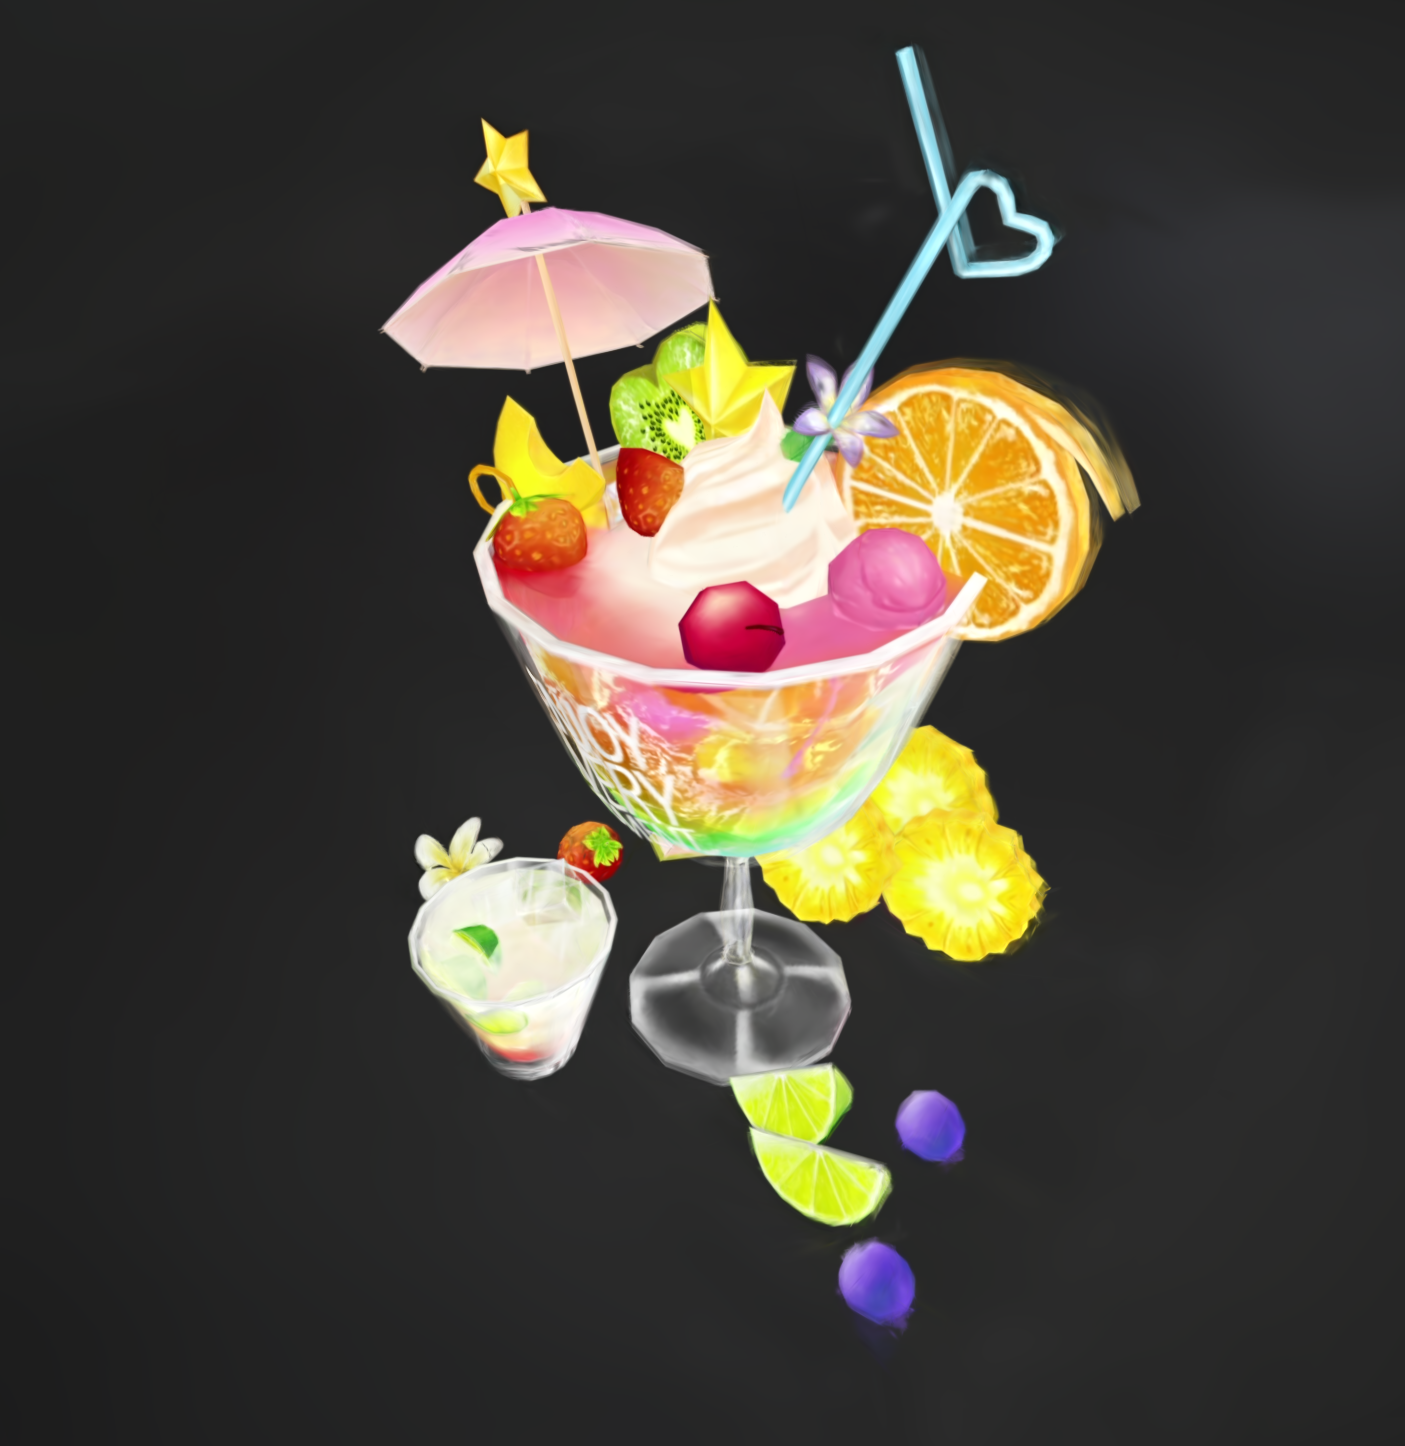

### Camera 2: 00002.png

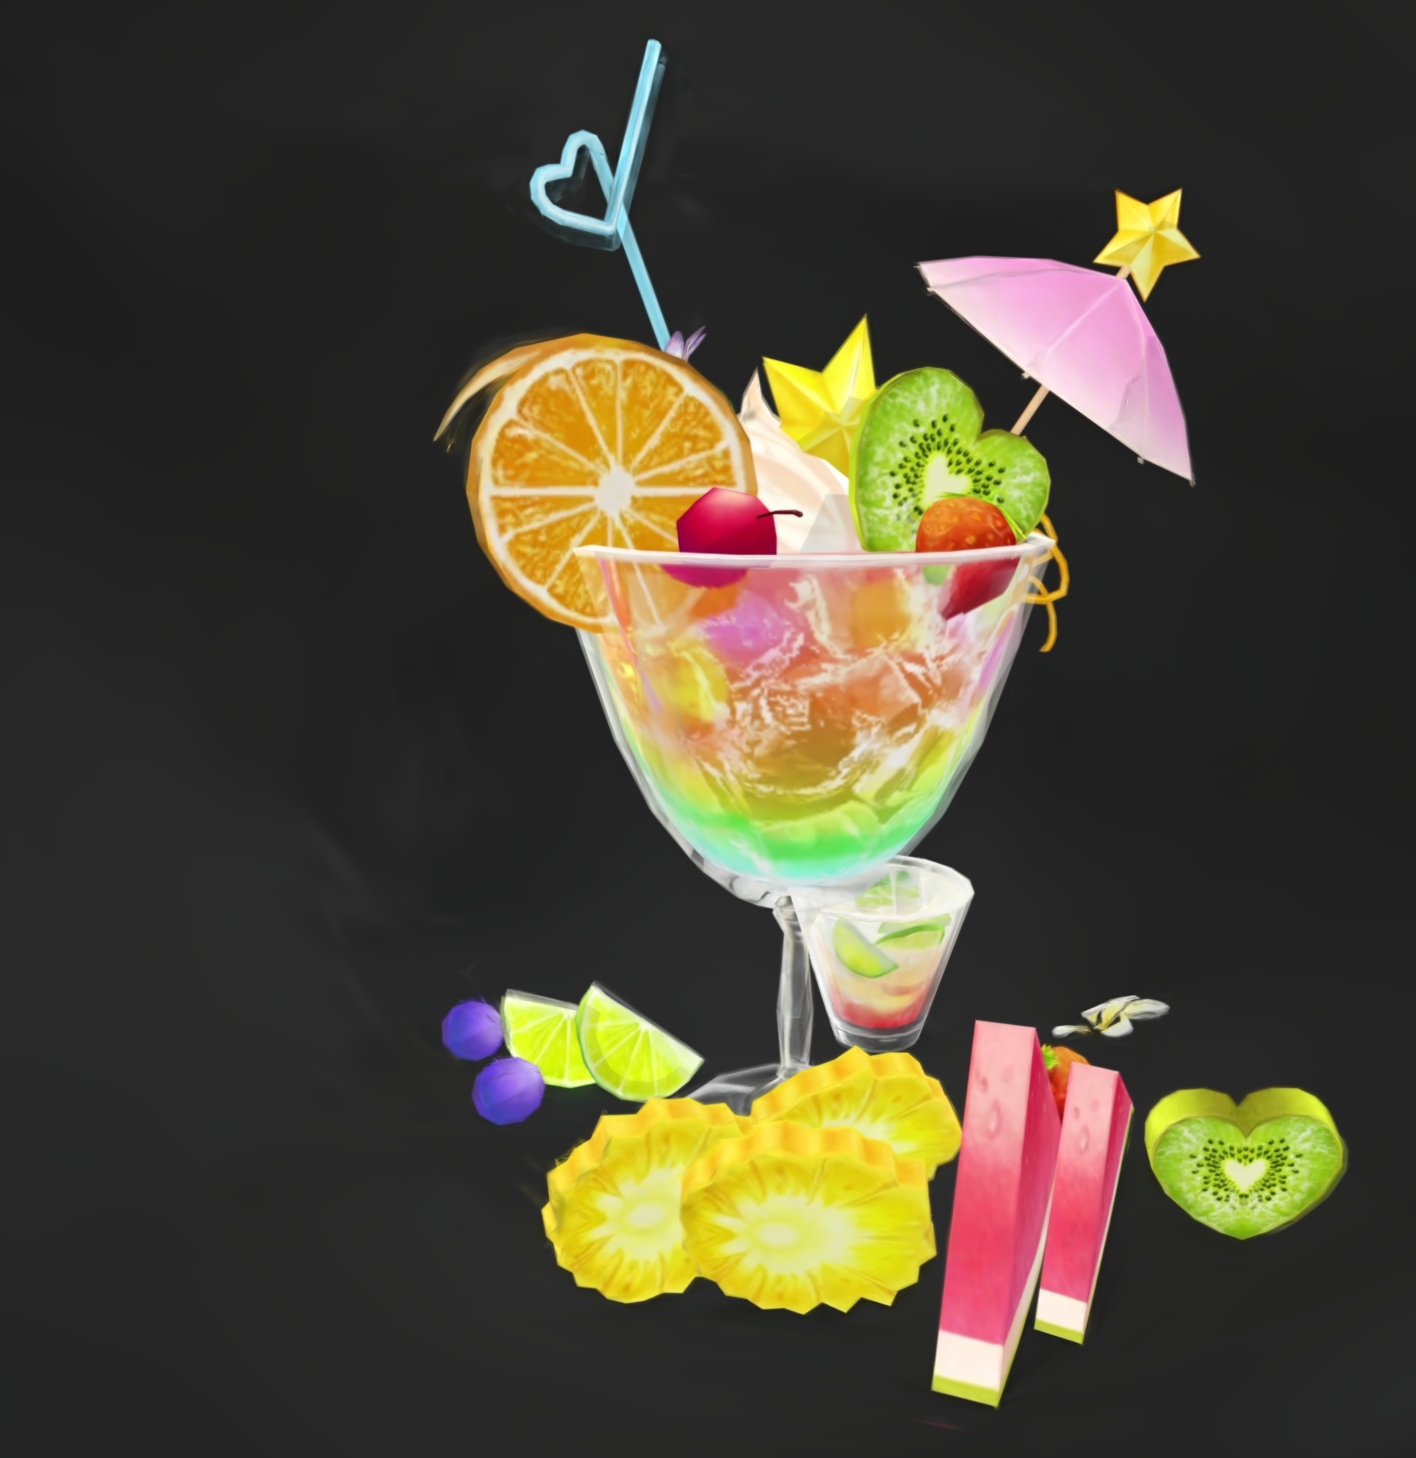

### Camera 3: 00003.png

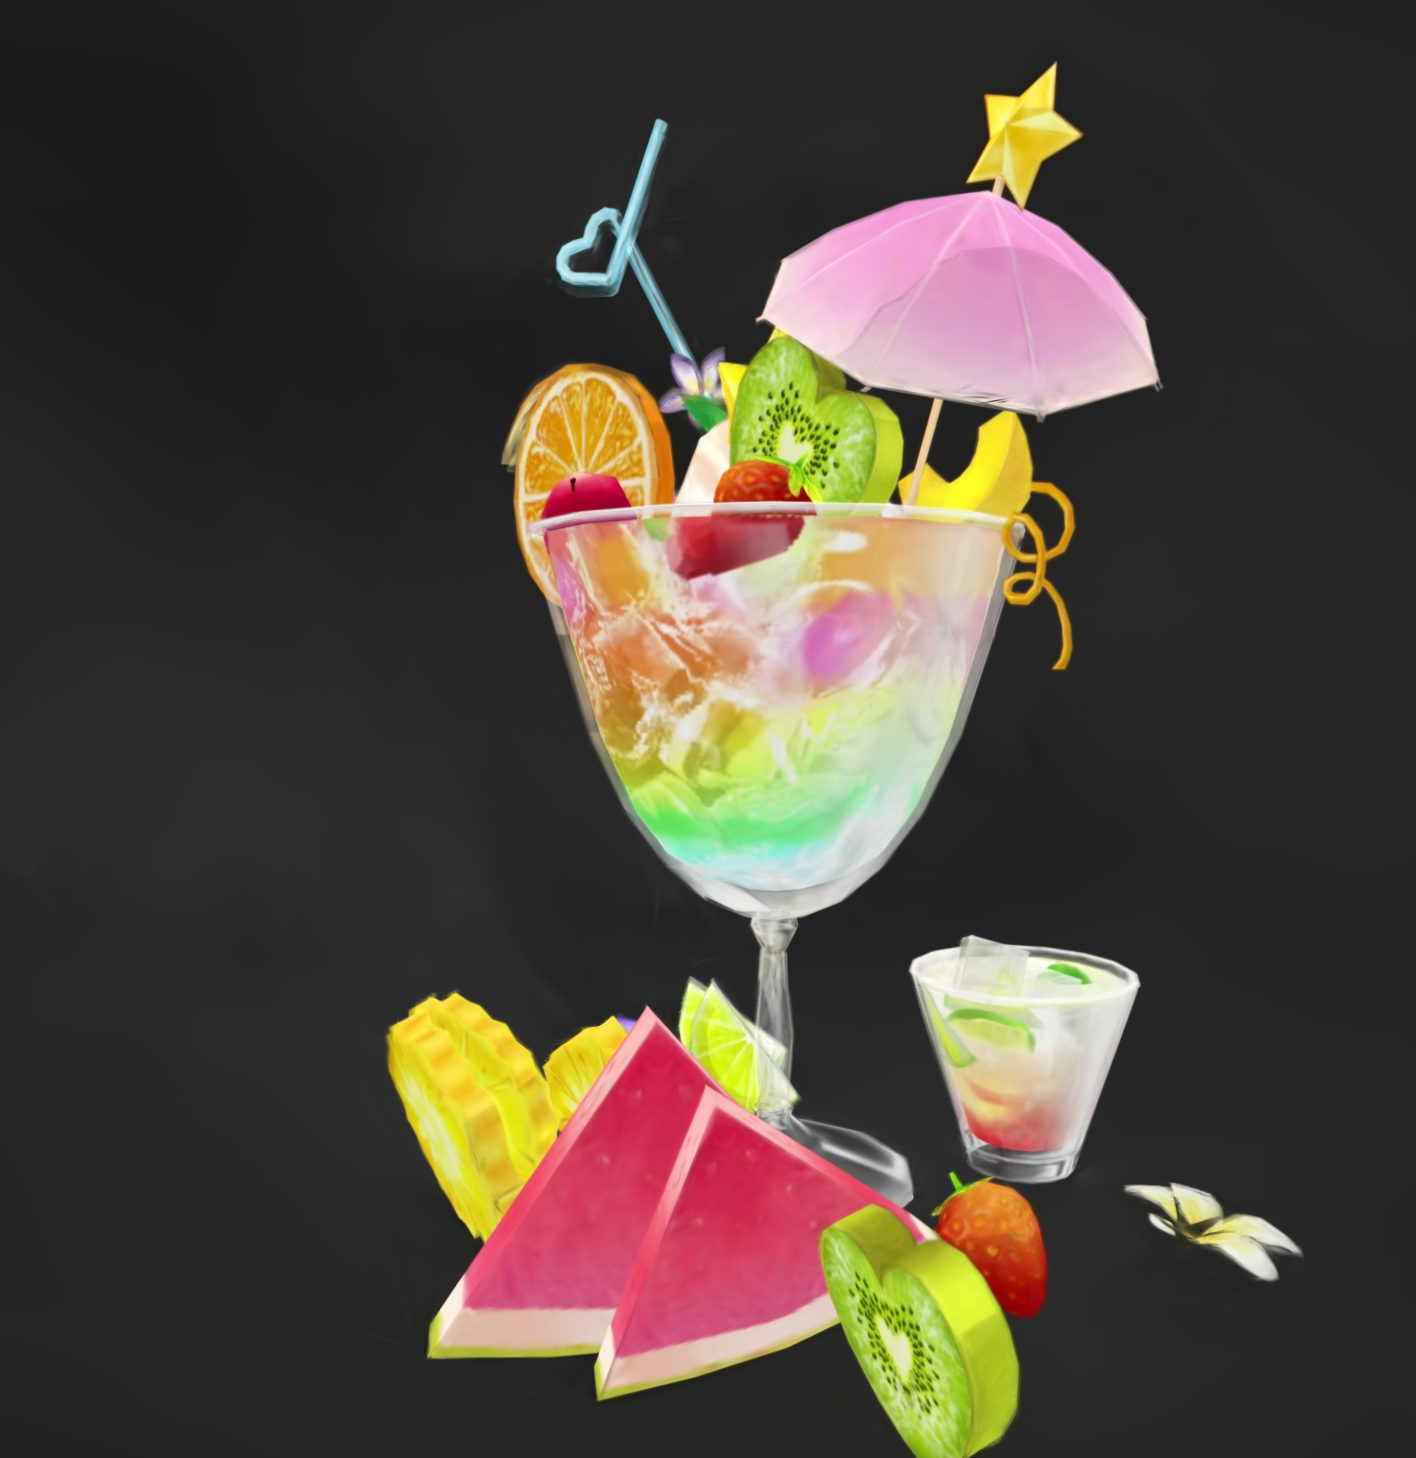

### Camera 4: 00004.png

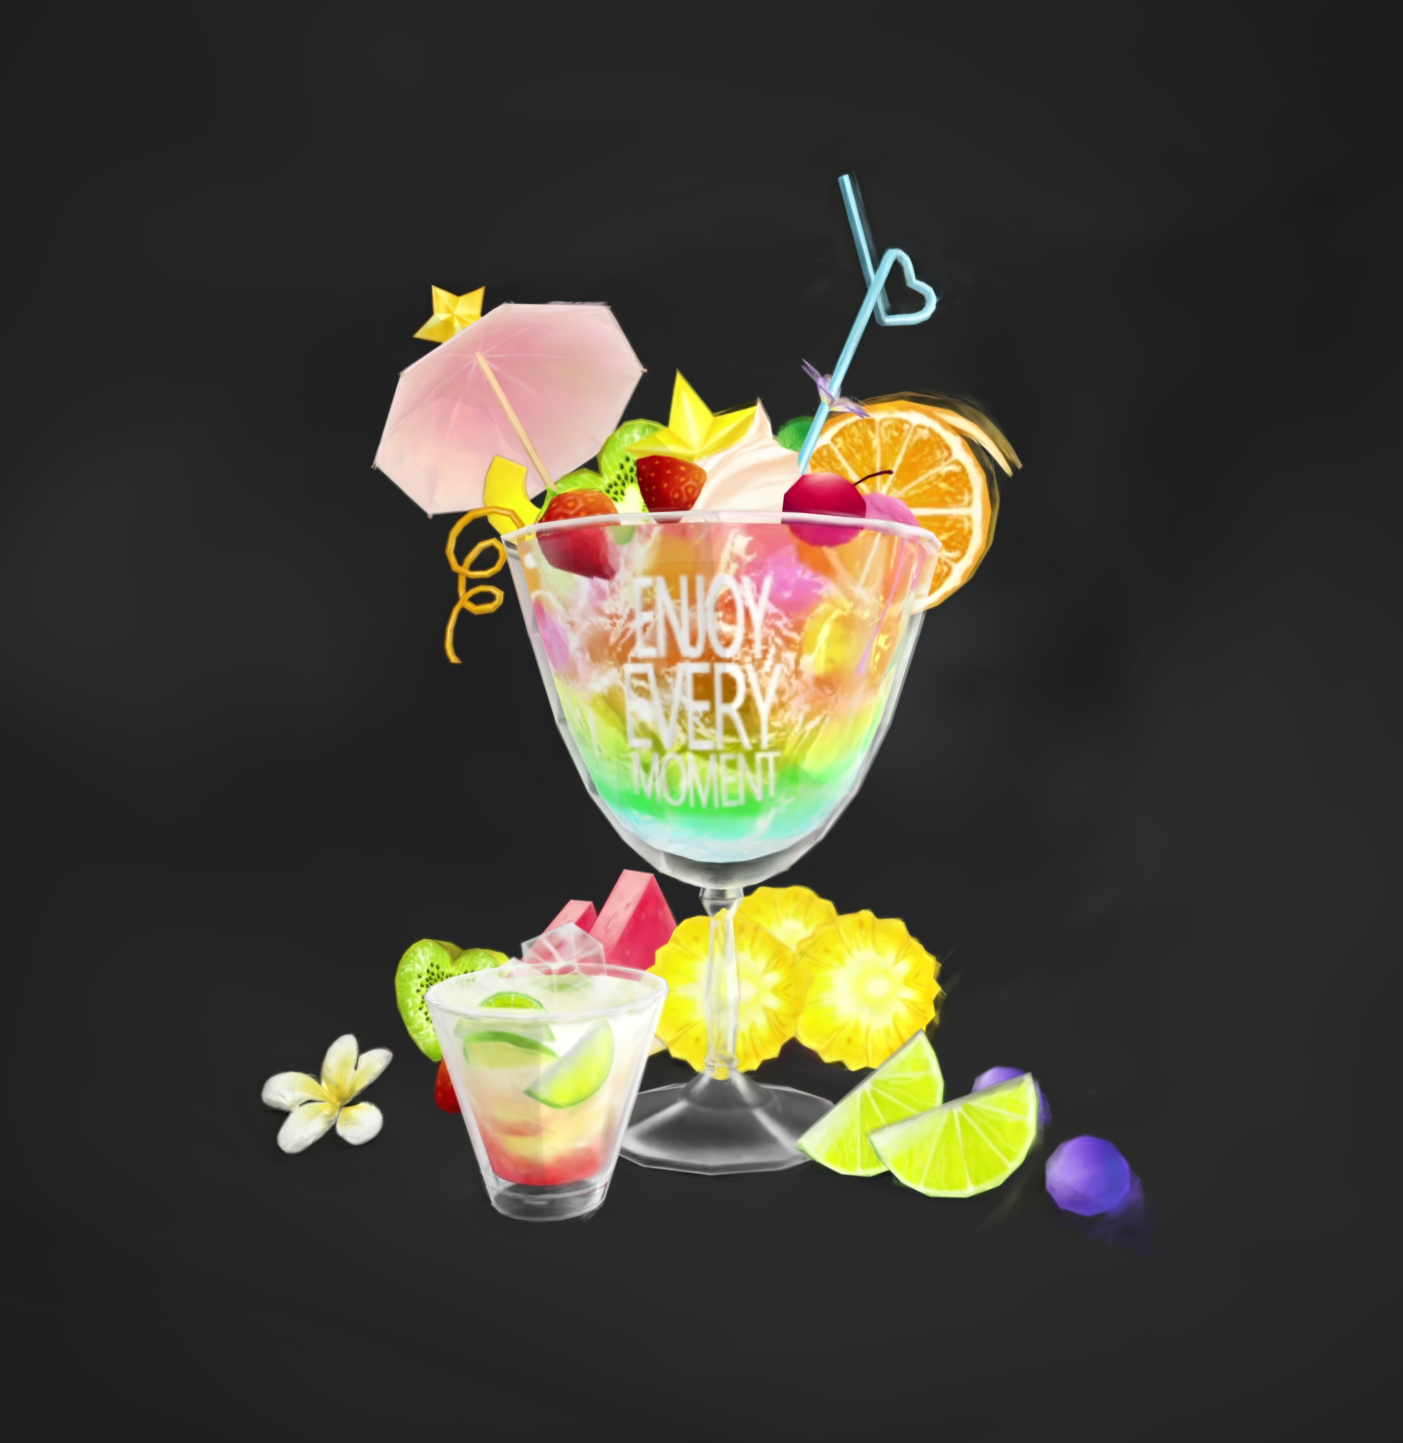

In [5]:
import pathlib
import subprocess
import sys
import time
import IPython.display

render_start = time.perf_counter()
subprocess.run([sys.executable, 'render.py'], cwd=assignment_root, check=True)
render_seconds = time.perf_counter() - render_start

render_files = sorted((assignment_root / 'renders').glob('*.png'))
if len(render_files) != 5:
    raise AssertionError(f'Expected five rendered PNGs, found {len(render_files)}')
for image_path in render_files:
    if image_path.stat().st_size == 0:
        raise AssertionError(f'Rendered image is empty: {image_path}')

print(f'Rendered {len(render_files)} views in {render_seconds:.2f} seconds.')
for camera_index, image_path in enumerate(render_files):
    IPython.display.display(IPython.display.Markdown(f'### Camera {camera_index}: {image_path.name}'))
    IPython.display.display(IPython.display.Image(filename=str(image_path)))